# DSC 411/511 Project
# Notebook 10: RQ8 (new): Underinsurance: How Many Flooded Homes Had Damage Above Their Coverage, by How Much, and Who?

**Class topics:** Lecture 03 (aggregation, discretization into quintiles), Lecture 07 (linear and logistic regression,
reading coefficients, cross-validation, leakage), Lecture 05 (tree models), plus two regression extensions:
**quantile regression** and the **Tweedie GLM** (a model for amounts with many exact zeros).

---

**How this question was derived.** Notebook 09 (RQ7) studied the **protection gap between places**: who files no claim
at all. This notebook looks at a second gap, **inside** the claims: a home *was* insured, but the damage was larger than
the coverage it had. Published work measures this gap with *expected* (modelled) flood damage:
- Amornsiripanitch, Biswas, Orellana-Li & Zink (Federal Reserve Bank of Philadelphia Working Paper 24-23, December 2024;
  published as *Measuring flood underinsurance in the USA*, Nature Climate Change, 2025) combine First Street Foundation
  expected damage with NFIP policies. They find that about **70% of expected annual flood losses** of single-family homes
  would be uninsured, and that underinsurance falls more on low-income communities. Their protection gap is the expected
  damage **above the coverage limit** (zero coverage for uninsured homes).

We cannot see uninsured homes here, but we can do something the paper could not: use the **actual damage written by the
adjuster** for every insured home that flooded. So we compute the same kind of measure (damage above coverage) with
observed damage, for the insured homes only.

> **RQ8. Among insured homes that flooded in 2020-2025, how many had building damage above their building coverage, how
> large was the shortfall, and which homes were most affected (neighbourhood income, renters, flood zone, primary
> residence)?**

**Framing.** This is a **descriptive and explanatory** question about what happened. The shortfall is built from the
adjuster's damage, so it is known only after the claim is adjusted. The regression sections explain the pattern; they are
not a tool to use at claim time. One section (Section 6) does test prediction with only pre-flood facts, for comparison.

---
# Section 0: Setup

In [1]:
import sys
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lightgbm as lgb
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_tweedie_deviance, mean_pinball_loss, roc_auc_score

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 200)
notebook_start = time.time()

claims = load_clean_claims()
print(f'All cleaned claims 2020-2025: {len(claims):,}')

All cleaned claims 2020-2025: 253,124


---
# Section 1: Data Used and Excluded

**Which rows.** A "flooded home" is a claim on a **residential building where people live in their own unit or small
building**: single-family homes, 2-4 family buildings and mobile homes (`occupancy_group`), with **building damage above
\$0** (`buildingDamageAmount > 0`). We exclude condominium association policies (one policy covers a whole building, with a
different coverage limit), large multi-family buildings and non-residential buildings, because "damage above coverage"
means something different for them.

| Column | Role | Note |
|---|---|---|
| `buildingDamageAmount` | damage (actual cash value) | written by the adjuster; the base of the shortfall |
| `totalBuildingInsuranceCoverage` | building coverage limit | NFIP maximum for a home is \$250,000 |
| `building_deductible_usd` | deductible | from `buildingDeductibleCode` (notebook 01) |
| `contentsDamageAmount`, `totalContentsInsuranceCoverage` | contents damage and coverage | second, contents measure |
| `buildingReplacementCost` | cost to rebuild | **leak-suspect** (filled in during adjustment, notebook 01); used here only descriptively |
| `buildingPropertyValue` | value of the building before the flood | adjuster value; used only in the explanatory model M2 |
| ACS (`acs_median_household_income`, `acs_pct_owner_occupied`) | neighbourhood | block group; renters = 100 - % owner-occupied |
| `flood_zone_group`, `primaryResidenceIndicator`, `rentalPropertyIndicator` | policy facts | |
| PRISM rain, HURDAT2 storm, coast distance | hazard controls | |

**Excluded columns:** payment amounts (they are capped by the coverage, so they would hide the shortfall), non-payment
reasons, ICC payments. **Dollars are nominal** (not adjusted for inflation). Inflation from 2020 to 2025 was roughly 20%;
a CPI file is not part of the project data, so we report nominal dollars and compare **shares** across years.

In [2]:
HOME_TYPES = ['single_family', 'multi_family_2to4', 'mobile_home']
homes = claims[claims['occupancy_group'].isin(HOME_TYPES) & (claims['buildingDamageAmount'] > 0)].copy()
homes['renter_share_pct'] = 100 - homes['acs_pct_owner_occupied']
print(f'Flooded homes (damage > 0): {len(homes):,} of {len(claims):,} claims')
print(homes['occupancy_group'].value_counts().to_string())
print(f"\nCoverage at the $250,000 maximum: {(homes['totalBuildingInsuranceCoverage'] >= 250_000).mean() * 100:.1f}% of flooded homes")

Flooded homes (damage > 0): 188,562 of 253,124 claims
occupancy_group
single_family        173944
multi_family_2to4     10180
mobile_home            4438

Coverage at the $250,000 maximum: 59.9% of flooded homes


---
# Section 2: Four Ways to Measure the Shortfall (step by step)

For each flooded home *i* with damage $D_i$, coverage $C_i$ and deductible $d_i$:

1. **Damage above the coverage limit** (main measure, the same idea as the Philadelphia Fed protection gap):
   $G_i = \max(D_i - C_i, 0)$. A home is **underinsured** if $G_i > 0$.
2. **Out of pocket under the policy terms:** the NFIP pays the damage minus the deductible, up to the limit. So the owner
   pays $O_i = D_i - \min(\max(D_i - d_i, 0), C_i)$. This includes the deductible, so almost everyone pays something.
   The **out-of-pocket share** is $O_i / D_i$.
3. **Contents not covered:** $\max(\text{contents damage} - \text{contents coverage}, 0)$. Homes without contents cover
   pay all contents damage themselves.
4. **Coverage below 80% of the replacement cost** (NFIP rule for replacement-cost settlement of a primary single-family
   home). This uses the leak-suspect replacement cost, so it is shown only as a description.

Measure 1 is a **lower bound** of the real gap: the damage is in actual cash value (depreciated), and some costs (living
elsewhere, outbuildings) are not in `buildingDamageAmount`.

In [3]:
homes['shortfall_above_limit'] = (homes['buildingDamageAmount'] - homes['totalBuildingInsuranceCoverage']).clip(lower=0)
homes['is_underinsured'] = (homes['shortfall_above_limit'] > 0).astype(int)
covered_payment = (homes['buildingDamageAmount'] - homes['building_deductible_usd']).clip(lower=0).clip(upper=homes['totalBuildingInsuranceCoverage'])
homes['out_of_pocket'] = homes['buildingDamageAmount'] - covered_payment
homes['out_of_pocket_share'] = homes['out_of_pocket'] / homes['buildingDamageAmount']
homes['contents_not_covered'] = (homes['contentsDamageAmount'].fillna(0) - homes['totalContentsInsuranceCoverage'].fillna(0)).clip(lower=0)
homes['coverage_below_80pct_replacement'] = np.where(homes['buildingReplacementCost'] > 0,
                                                     (homes['totalBuildingInsuranceCoverage'] < 0.8 * homes['buildingReplacementCost']).astype(float), np.nan)

total_damage = homes['buildingDamageAmount'].sum()
measure_rows = [
    {'measure': '1. damage above coverage limit', 'homes_affected_%': homes['is_underinsured'].mean() * 100,
     'homes_affected': int(homes['is_underinsured'].sum()),
     'median_if_affected_$': homes.loc[homes['is_underinsured'] == 1, 'shortfall_above_limit'].median(),
     'p90_if_affected_$': homes.loc[homes['is_underinsured'] == 1, 'shortfall_above_limit'].quantile(0.9),
     'total_$million': homes['shortfall_above_limit'].sum() / 1e6, 'share_of_building_damage_%': homes['shortfall_above_limit'].sum() / total_damage * 100},
    {'measure': '2. out of pocket (deductible + above limit)', 'homes_affected_%': (homes['out_of_pocket'] > 0).mean() * 100,
     'homes_affected': int((homes['out_of_pocket'] > 0).sum()),
     'median_if_affected_$': homes.loc[homes['out_of_pocket'] > 0, 'out_of_pocket'].median(),
     'p90_if_affected_$': homes.loc[homes['out_of_pocket'] > 0, 'out_of_pocket'].quantile(0.9),
     'total_$million': homes['out_of_pocket'].sum() / 1e6, 'share_of_building_damage_%': homes['out_of_pocket'].sum() / total_damage * 100},
    {'measure': '3. contents damage not covered', 'homes_affected_%': (homes['contents_not_covered'] > 0).mean() * 100,
     'homes_affected': int((homes['contents_not_covered'] > 0).sum()),
     'median_if_affected_$': homes.loc[homes['contents_not_covered'] > 0, 'contents_not_covered'].median(),
     'p90_if_affected_$': homes.loc[homes['contents_not_covered'] > 0, 'contents_not_covered'].quantile(0.9),
     'total_$million': homes['contents_not_covered'].sum() / 1e6,
     'share_of_building_damage_%': np.nan},
    {'measure': '4. coverage < 80% of replacement cost (leak-suspect column)', 'homes_affected_%': homes['coverage_below_80pct_replacement'].mean() * 100,
     'homes_affected': int(homes['coverage_below_80pct_replacement'].sum()), 'median_if_affected_$': np.nan, 'p90_if_affected_$': np.nan,
     'total_$million': np.nan, 'share_of_building_damage_%': np.nan},
]
measure_table = pd.DataFrame(measure_rows).round(2)
measure_table.to_csv(TABLE_DIR / '10_rq8_shortfall_measures.csv', index=False)
print(f'Flooded homes: {len(homes):,}; total building damage ${total_damage / 1e9:.2f} billion (nominal)')
print(measure_table.to_string(index=False))

Flooded homes: 188,562; total building damage $11.18 billion (nominal)
                                                    measure  homes_affected_%  homes_affected  median_if_affected_$  p90_if_affected_$  total_$million  share_of_building_damage_%
                             1. damage above coverage limit              5.33           10050               11273.0            55510.9          265.44                        2.37
                2. out of pocket (deductible + above limit)            100.00          188562                2000.0             7536.0          780.96                        6.98
                             3. contents damage not covered              9.61           18117                5629.0            24138.4          639.43                         NaN
4. coverage < 80% of replacement cost (leak-suspect column)             54.82          103368                   NaN                NaN             NaN                         NaN


**How to read this.** The four measures give very different pictures, so the definition matters.

1. **Damage above the coverage limit** (the Philadelphia Fed style measure using the actual damage) hits **5.3% of flooded homes** (10,050). The median gap is \$11,273 and the P90 is \$55,511. In total it is \$265 million, only 2.4% of the \$11.18 billion building damage.
2. **Out of pocket including the deductible** hits every home by definition. The median is \$2,000 and the total is \$781 million (7.0% of damage). The deductible is the larger part for most homes.
3. **Contents damage not covered** hits 9.6% of homes (\$639 million), more than twice the dollars of measure 1.
4. **Coverage below 80% of replacement cost** (the insurance-industry rule) would call **54.8%** of homes underinsured. But the replacement-cost column is filled by the adjuster and is missing mostly for unpaid claims (the notebook 01/03 leak), so we only report it and do not use it as the main measure.

All dollars are nominal (no CPI adjustment), so 2020 and 2025 amounts are not exactly comparable.

---
# Section 3: How Many and How Much, by Year, Storm and Coverage Level (aggregation, Lecture 03)

In [4]:
by_year = homes.groupby('loss_year').agg(flooded_homes=('id', 'size'), underinsured_pct=('is_underinsured', 'mean'),
                                         median_damage=('buildingDamageAmount', 'median'),
                                         shortfall_total_million=('shortfall_above_limit', lambda s: s.sum() / 1e6),
                                         median_shortfall_if_any=('shortfall_above_limit', lambda s: s[s > 0].median()))
by_year['underinsured_pct'] *= 100
big_events = homes['event_group'].value_counts().head(8).index
by_event = homes[homes['event_group'].isin(big_events)].groupby('event_group').agg(
    flooded_homes=('id', 'size'), underinsured_pct=('is_underinsured', 'mean'),
    shortfall_total_million=('shortfall_above_limit', lambda s: s.sum() / 1e6),
    median_shortfall_if_any=('shortfall_above_limit', lambda s: s[s > 0].median())).sort_values('flooded_homes', ascending=False)
by_event['underinsured_pct'] *= 100
homes['coverage_band'] = pd.cut(homes['totalBuildingInsuranceCoverage'], [0, 100_000, 150_000, 200_000, 249_999, 10**9],
                                labels=['<=100k', '100-150k', '150-200k', '200-250k', 'at 250k max'])
by_coverage = homes.groupby('coverage_band', observed=True).agg(flooded_homes=('id', 'size'), underinsured_pct=('is_underinsured', 'mean'),
                                                                median_damage=('buildingDamageAmount', 'median'),
                                                                median_property_value=('buildingPropertyValue', 'median'))
by_coverage['underinsured_pct'] *= 100
by_year.round(1).to_csv(TABLE_DIR / '10_rq8_by_year.csv')
by_event.round(1).to_csv(TABLE_DIR / '10_rq8_by_event.csv')
by_coverage.round(1).to_csv(TABLE_DIR / '10_rq8_by_coverage_band.csv')
print('By loss year:'); print(by_year.round(1).to_string())
print('\nLargest events:'); print(by_event.round(1).to_string())
print('\nBy coverage band:'); print(by_coverage.round(1).to_string())

By loss year:
           flooded_homes  underinsured_pct  median_damage  shortfall_total_million  median_shortfall_if_any
loss_year                                                                                                  
2020               22535               2.9        11911.0                      9.2                   7565.5
2021               31500               3.7        21146.5                     19.2                   8861.5
2022               38864               7.4        42034.0                     79.6                  12158.0
2023               14644               2.2        27239.0                      5.5                   8646.0
2024               72087               6.1        63817.0                    136.1                  12275.0
2025                8932               7.1        26044.5                     15.9                  11944.0

Largest events:
                     flooded_homes  underinsured_pct  shortfall_total_million  median_shortfall_if_any
ev

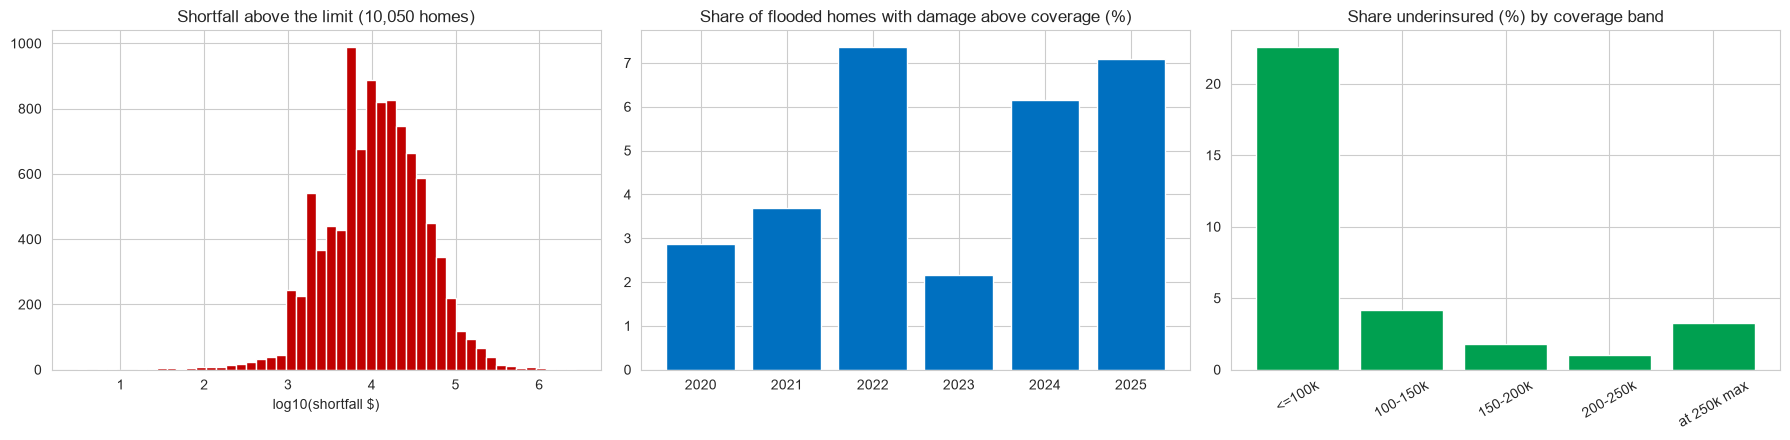

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
affected = homes.loc[homes['is_underinsured'] == 1, 'shortfall_above_limit']
axes[0].hist(np.log10(affected), bins=50, color='#C00000')
axes[0].set_xlabel('log10(shortfall $)'); axes[0].set_title(f'Shortfall above the limit ({len(affected):,} homes)')
axes[1].bar(by_year.index.astype(str), by_year['underinsured_pct'], color='#0070C0')
axes[1].set_title('Share of flooded homes with damage above coverage (%)')
axes[2].bar(by_coverage.index.astype(str), by_coverage['underinsured_pct'], color='#00A050')
axes[2].set_title('Share underinsured (%) by coverage band'); axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(FIGURE_DIR / '10_rq8_shortfall_overview.png', dpi=120); plt.show()

**How to read this.**

- **Years and storms:** the underinsured share is highest in the big-hurricane years: 7.4% in 2022 (Ian), 6.1% in 2024 (Helene, Milton) and 7.1% in 2025. It is 2-4% in the other years. Helene (8.0%, \$111 million) and Ian (8.0%, \$72 million) together make up two thirds of the total shortfall.
- **Coverage level:** the share falls sharply with the coverage bought: 22.6% of homes insured for \$100k or less are underinsured, against 1.0-4.2% between \$100k and \$250k. At the \$250k maximum the share rises again to 3.3%, because there the limit is set by the program, not by the owner.

---
# Section 4: Who? Raw Comparisons by Neighbourhood and Policy Facts (discretization, Lecture 03)

Income and renter share are split into **quintiles** over the flooded homes (so each group holds about 20% of homes).
These are **raw** shares, before any control.

In [6]:
homes['income_quintile'] = pd.qcut(homes['acs_median_household_income'], 5, labels=['Q1_lowest', 'Q2', 'Q3', 'Q4', 'Q5_highest'])
homes['renter_quintile'] = pd.qcut(homes['renter_share_pct'].rank(method='first'), 5, labels=['R1_fewest', 'R2', 'R3', 'R4', 'R5_most'])
homes['primary_residence'] = homes['primaryResidenceIndicator'].map({1: 'primary', 0: 'second_or_other'})
homes['rental_property'] = homes['rentalPropertyIndicator'].map({1: 'rental', 0: 'not_rental'})


def who_table(group_column):
    table = homes.groupby(group_column, observed=True).agg(
        flooded_homes=('id', 'size'), underinsured_pct=('is_underinsured', 'mean'),
        median_shortfall_if_any=('shortfall_above_limit', lambda s: s[s > 0].median()),
        mean_out_of_pocket_share=('out_of_pocket_share', 'mean'), median_damage=('buildingDamageAmount', 'median'),
        median_coverage=('totalBuildingInsuranceCoverage', 'median'), median_property_value=('buildingPropertyValue', 'median'))
    table['underinsured_pct'] *= 100
    table['mean_out_of_pocket_share'] *= 100
    return table.round(1)


who_tables = {}
for column in ['income_quintile', 'renter_quintile', 'flood_zone_group', 'primary_residence', 'rental_property']:
    who_tables[column] = who_table(column)
    who_tables[column].to_csv(TABLE_DIR / f'10_rq8_who_{column}.csv')
    print(f'\nBy {column}:'); print(who_tables[column].to_string())


By income_quintile:
                 flooded_homes  underinsured_pct  median_shortfall_if_any  mean_out_of_pocket_share  median_damage  median_coverage  median_property_value
income_quintile                                                                                                                                           
Q1_lowest                37958               7.0                  10533.0                      20.3        29720.5         196000.0               159326.5
Q2                       37468               5.3                  10522.5                      20.1        33441.5         242000.0               178700.5
Q3                       37881               4.9                  11300.0                      19.6        36560.0         250000.0               203877.0
Q4                       37542               4.3                  11790.0                      19.7        33705.5         250000.0               222117.0
Q5_highest               37713               5.1 

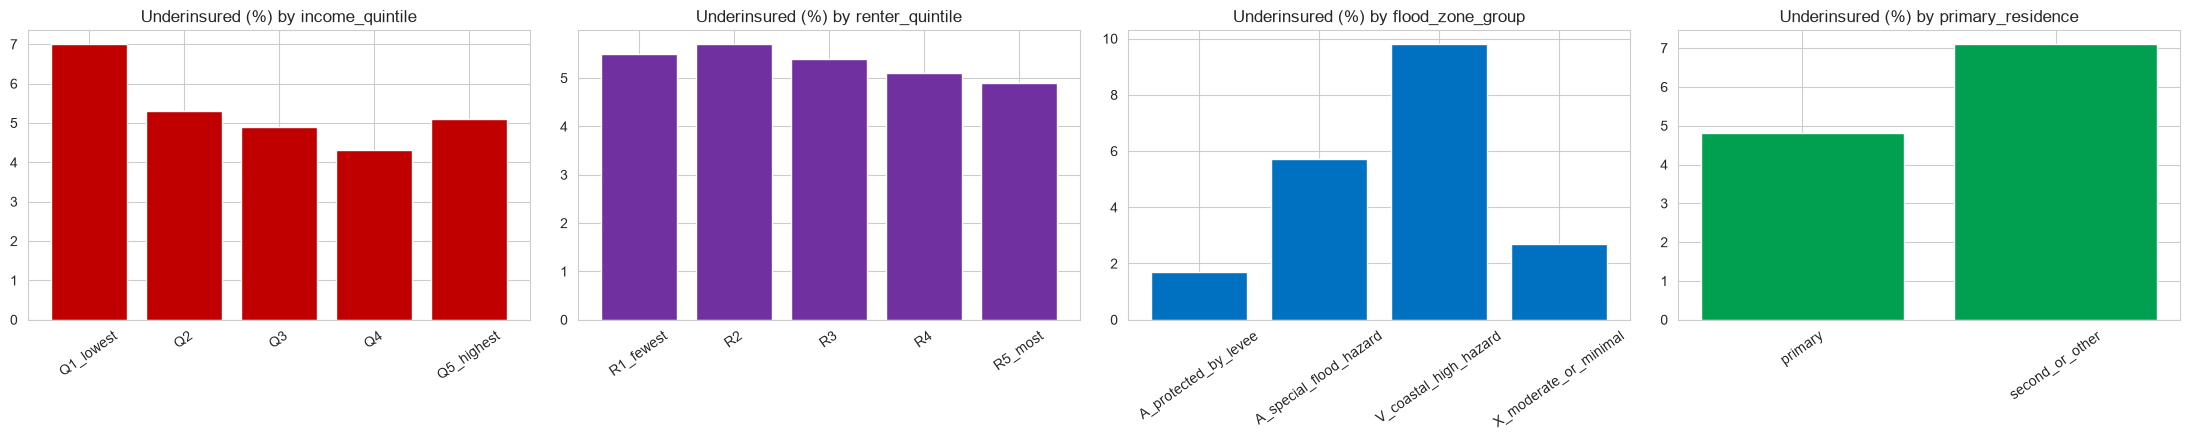

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, column, color in zip(axes, ['income_quintile', 'renter_quintile', 'flood_zone_group', 'primary_residence'],
                             ['#C00000', '#7030A0', '#0070C0', '#00A050']):
    table = who_tables[column]
    table = table[table['flooded_homes'] >= 200]
    ax.bar(table.index.astype(str), table['underinsured_pct'], color=color)
    ax.set_title(f'Underinsured (%) by {column}'); ax.tick_params(axis='x', rotation=35)
plt.tight_layout(); plt.savefig(FIGURE_DIR / '10_rq8_who.png', dpi=120); plt.show()

**How to read this (raw shares, no controls).**

- **Income:** 7.0% of homes are underinsured in the lowest-income quintile, against 4.3-5.1% in the others. Lower-income areas have lower coverage (median \$196,000 against \$250,000).
- **Renters:** the share falls slightly from 5.5% (fewest renters) to 4.9% (most renters).
- **Flood zone:** the share is highest in coastal zone V (9.8%), against 5.7% in zone A and 2.7% in zone X.
- **Second homes** (7.1%) are underinsured more often than primary residences (4.8%).
- The **out-of-pocket share** of damage is about 20% in every group, a little higher in the lowest-income quintile (20.3%) and in zone V (28.9%).

---
# Section 5: Explaining Who Is Underinsured: Three Regression Models

Raw shares mix many things: richer areas have more expensive homes, coastal areas have stronger storms. We add controls.
All models use the same **explanatory variables**: income (log, standardised), renter share (standardised), flood zone,
primary residence, rental property, and **hazard controls** (3-day rain, storm distance and category, coast distance),
plus **state and loss-year fixed effects**. Standard errors are clustered by county (claims in one county share a storm
and a local market). Model **M2** also adds the log building value (adjuster value), to ask: is it only about expensive
homes?

**5.1 Logistic regression (Lecture 07): who has any shortfall?**
1. Let $p_i = P(G_i > 0)$. We model the log-odds as a straight line: $\log \frac{p_i}{1-p_i} = \beta_0 + \beta_1 x_{1i} + \dots$
2. The coefficients are found by maximum likelihood. $e^{\beta}$ is an **odds ratio**: the odds are multiplied by
   $e^{\beta}$ when $x$ goes up by one unit (one standard deviation for the standardised variables).

**5.2 Tweedie GLM: how many dollars of shortfall?** The shortfall is exactly zero for most homes and a large positive
amount for a few. A normal linear model fits this badly. The **Tweedie** distribution with power $1 < p < 2$ is a
compound Poisson-gamma: a Poisson number of gamma-sized amounts. It has a point mass at zero and a long right tail, so it
fits "many zeros + skewed amounts" in one model. We use a log link: $\log E[G_i] = x_i^\top \beta$, so $e^{\beta}$
multiplies the **expected shortfall**. We use $p = 1.5$.

**5.3 Quantile regression: how large is the shortfall when there is one?** Least squares models the **mean**. Quantile
regression (Koenker & Bassett 1978) models a chosen **quantile** $\tau$ (for example the median, $\tau = 0.5$, or the
90th percentile, $\tau = 0.9$). Step by step:
1. For a residual $u = y - x^\top\beta$, use the "check" (pinball) loss $\rho_\tau(u) = u(\tau - 1[u < 0])$: positive
   residuals cost $\tau$ per dollar, negative residuals cost $1 - \tau$.
2. Minimise $\sum_i \rho_\tau(y_i - x_i^\top \beta)$. For $\tau = 0.5$ this is the least absolute deviation (median).
3. A coefficient is then "how much the $\tau$-quantile of the shortfall changes when $x$ goes up by one unit".
We fit it on the homes **with** a shortfall, for $\tau = 0.5$ and $\tau = 0.9$.

In [8]:
model_homes = homes.dropna(subset=['acs_median_household_income', 'renter_share_pct', 'rain_3day_mm', 'coast_distance_km']).copy()
model_homes = model_homes[model_homes['state'].map(model_homes['state'].value_counts()) >= 50]
model_homes['log_income'] = np.log(model_homes['acs_median_household_income'])
model_homes['log_storm_distance'] = np.log1p(model_homes['storm_distance_km'].fillna(model_homes['storm_distance_km'].max()))
model_homes['log_coast_distance'] = np.log1p(model_homes['coast_distance_km'])
model_homes['storm_category'] = model_homes['storm_category_at_closest'].fillna(0)
model_homes['log_property_value'] = np.log(model_homes['buildingPropertyValue'].where(model_homes['buildingPropertyValue'] > 0))
for column in ['log_income', 'renter_share_pct', 'rain_3day_mm', 'log_storm_distance', 'log_coast_distance', 'log_property_value']:
    model_homes[f'z_{column}'] = (model_homes[column] - model_homes[column].mean()) / model_homes[column].std()
model_homes['zone'] = model_homes['flood_zone_group'].where(model_homes['flood_zone_group'].isin(
    ['A_special_flood_hazard', 'X_moderate_or_minimal', 'V_coastal_high_hazard']), 'other')
model_homes['county'] = model_homes['county_geoid'].fillna('unknown')
# States with very few underinsured homes are pooled, so the logistic model does not meet perfect separation.
underinsured_by_state = model_homes.groupby('state')['is_underinsured'].sum()
model_homes['state_group'] = model_homes['state'].where(model_homes['state'].map(underinsured_by_state) >= 20, 'other_states')
WHO_TERMS = ("z_log_income + z_renter_share_pct + C(zone, Treatment('A_special_flood_hazard')) + primaryResidenceIndicator"
             " + rentalPropertyIndicator")
HAZARD_TERMS = 'z_rain_3day_mm + z_log_storm_distance + storm_category + z_log_coast_distance + C(state_group) + C(loss_year)'
FORMULA_M1 = f'{WHO_TERMS} + {HAZARD_TERMS}'
FORMULA_M2 = f'{FORMULA_M1} + z_log_property_value'
m2_rows = model_homes.dropna(subset=['z_log_property_value'])
print(f'Homes in the models: M1 {len(model_homes):,}, M2 {len(m2_rows):,}; underinsured {model_homes["is_underinsured"].mean() * 100:.1f}%')

Homes in the models: M1 188,519, M2 177,796; underinsured 5.3%


In [9]:
KEY_TERMS = {'z_log_income': 'income (+1 SD of log income)', 'z_renter_share_pct': 'renter share (+1 SD)',
             "C(zone, Treatment('A_special_flood_hazard'))[T.X_moderate_or_minimal]": 'zone X vs zone A',
             "C(zone, Treatment('A_special_flood_hazard'))[T.V_coastal_high_hazard]": 'zone V vs zone A',
             'primaryResidenceIndicator': 'primary residence', 'rentalPropertyIndicator': 'rental property',
             'z_log_property_value': 'building value (+1 SD of log value)'}


effect_rows = []
logit_results = {}
for model_name, formula, data in [('M1', FORMULA_M1, model_homes), ('M2 (+ building value)', FORMULA_M2, m2_rows)]:
    result = smf.logit(f'is_underinsured ~ {formula}', data=data).fit(
        cov_type='cluster', cov_kwds={'groups': pd.factorize(data['county'])[0]}, disp=0, maxiter=200)
    logit_results[model_name] = result
    for term, label in KEY_TERMS.items():
        if term in result.params:
            low, high = result.conf_int().loc[term]
            effect_rows.append({'model': f'logit {model_name}', 'term': label, 'effect': np.exp(result.params[term]),
                                'ci_low': np.exp(low), 'ci_high': np.exp(high), 'p_value': result.pvalues[term], 'scale': 'odds ratio'})

tweedie_results = {}
for model_name, formula, data in [('M1', FORMULA_M1, model_homes), ('M2 (+ building value)', FORMULA_M2, m2_rows)]:
    result = smf.glm(f'shortfall_above_limit ~ {formula}', data=data,
                     family=sm.families.Tweedie(var_power=1.5, link=sm.families.links.Log())).fit(
        cov_type='cluster', cov_kwds={'groups': pd.factorize(data['county'])[0]})
    tweedie_results[model_name] = result
    for term, label in KEY_TERMS.items():
        if term in result.params:
            low, high = result.conf_int().loc[term]
            effect_rows.append({'model': f'Tweedie {model_name}', 'term': label, 'effect': np.exp(result.params[term]),
                                'ci_low': np.exp(low), 'ci_high': np.exp(high), 'p_value': result.pvalues[term], 'scale': 'ratio of expected shortfall'})

underinsured_homes = model_homes[model_homes['is_underinsured'] == 1]
for quantile in [0.5, 0.9]:
    result = smf.quantreg(f'shortfall_above_limit ~ {WHO_TERMS} + z_rain_3day_mm + z_log_storm_distance + storm_category + z_log_coast_distance + C(loss_year)',
                          data=underinsured_homes).fit(q=quantile, max_iter=5000)
    for term, label in KEY_TERMS.items():
        if term in result.params:
            low, high = result.conf_int().loc[term]
            effect_rows.append({'model': f'quantile tau={quantile} (homes with shortfall)', 'term': label, 'effect': result.params[term],
                                'ci_low': low, 'ci_high': high, 'p_value': result.pvalues[term], 'scale': '$ change in the quantile'})
effects_table = pd.DataFrame(effect_rows)
effects_table.round(4).to_csv(TABLE_DIR / '10_rq8_regression_effects.csv', index=False)
with pd.option_context('display.max_rows', 100):
    print(effects_table.round(3).to_string(index=False))
print(f'\nHomes with a shortfall used in the quantile regression: {len(underinsured_homes):,} (no state effects: too few per state)')

                                  model                                term    effect    ci_low   ci_high  p_value                       scale
                               logit M1        income (+1 SD of log income)     0.887     0.802     0.981    0.019                  odds ratio
                               logit M1                renter share (+1 SD)     0.961     0.895     1.032    0.275                  odds ratio
                               logit M1                    zone X vs zone A     0.613     0.529     0.710    0.000                  odds ratio
                               logit M1                    zone V vs zone A     2.002     1.515     2.646    0.000                  odds ratio
                               logit M1                   primary residence     0.667     0.565     0.788    0.000                  odds ratio
                               logit M1                     rental property     0.839     0.703     1.001    0.052                  odds ratio

**How to read this (with hazard, state and year controls).**

- **Income:** one SD higher income goes with lower odds of any shortfall (OR 0.89 [0.80-0.98]; 0.87 [0.81-0.93] when the building value is added in M2). So the low-income gap is **not** only about cheaper homes.
- **Renter share:** no effect (OR 0.96 [0.90-1.03]).
- **Flood zone and residence:** zone V doubles the odds against zone A (2.00 [1.51-2.65]), and zone X lowers them (0.61). Primary residences have lower odds (0.67 [0.56-0.79]). Building value itself does not change the odds (1.05, n.s.).
- **Dollar size (Tweedie):** in M1, income has a ratio of 1.09 [0.99-1.22] (n.s.). Richer areas are underinsured less often, but when they are, the gap is not smaller. Building value multiplies the expected shortfall by 1.40 per SD in M2. Zone V multiplies it by 3.2.
- **Quantile regression** (homes with a shortfall): one SD more income raises the 90th percentile of the shortfall by \$9,248 [7,476-11,020], and the median by \$978. So the **largest gaps** are in richer areas with expensive homes above the \$250k cap, while **more frequent** gaps are in lower-income areas with low coverage.
- These are associations in observational data, not causal effects.

---
# Section 6: Can Pre-Flood Facts Predict the Shortfall? Linear Models vs LightGBM (time split)

The explanatory models above use the whole period. Here we ask a predictive question with the project's usual rules:
train on 2020-2023, test on 2024-2025, **only facts known before the adjuster arrived** (the NFIP, event and context
feature lists, checked with `check_no_leakage`). Two comparisons:

| Target | Linear model | Tree model | Score (lower is better) |
|---|---|---|---|
| shortfall above limit ($) | Tweedie GLM ($p$ = 1.5, log link) | LightGBM, `objective='tweedie'` | mean Tweedie deviance |
| out-of-pocket share (0-1) | linear quantile regression, $\tau = 0.9$ | LightGBM, `objective='quantile'`, $\alpha = 0.9$ | mean pinball loss at 0.9 |

Both comparisons also include a **constant baseline** (the training mean shortfall, or the training P90 of the share).
A model is only useful if it beats the constant.

On the training years we run a **5-fold event-grouped cross-validation** (all claims of one storm in the same fold) and
report the mean **and** the spread over folds. On the test years we report the difference between the two models with
a **95% event-block bootstrap** interval (`event_block_bootstrap`, 500 repeats). The linear quantile regression is fitted
on a 30,000-home random sample of the training rows to keep the run short (the LightGBM uses all rows).

In [10]:
PREDICT_NUMERIC = NFIP_NUMERIC_FEATURES + EVENT_FEATURES + CONTEXT_FEATURES
PREDICT_CATEGORICAL = NFIP_CATEGORICAL_FEATURES
check_no_leakage(PREDICT_NUMERIC + PREDICT_CATEGORICAL)
train_homes = homes[homes['loss_year'].isin(TRAIN_YEARS)].reset_index(drop=True)
test_homes = homes[homes['loss_year'].isin(TEST_YEARS)].reset_index(drop=True)
print(f'Train homes {len(train_homes):,} ({train_homes["event_group"].nunique()} events), test homes {len(test_homes):,} ({test_homes["event_group"].nunique()} events)')
QUANTILE = 0.9
LINEAR_SAMPLE = 30_000


def tweedie_deviance(y, prediction):
    return mean_tweedie_deviance(y, np.clip(prediction, 1e-3, None), power=1.5)


def pinball(y, prediction):
    return mean_pinball_loss(y, prediction, alpha=QUANTILE)


def fit_predict(model_name, fit_rows, score_rows):
    """Fit one of the models on fit_rows and return predictions for score_rows."""
    if model_name == 'training mean (baseline)':
        return np.full(len(score_rows), fit_rows['shortfall_above_limit'].mean())
    if model_name == 'training P90 (baseline)':
        return np.full(len(score_rows), fit_rows['out_of_pocket_share'].quantile(QUANTILE))
    if model_name.startswith('LightGBM'):
        objective = {'objective': 'tweedie', 'tweedie_variance_power': 1.5} if 'Tweedie' in model_name else {'objective': 'quantile', 'alpha': QUANTILE}
        target = 'shortfall_above_limit' if 'Tweedie' in model_name else 'out_of_pocket_share'
        model = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8,
                                  subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1, **objective)
        model.fit(to_category_frame(fit_rows, PREDICT_NUMERIC, PREDICT_CATEGORICAL), fit_rows[target])
        return model.predict(to_category_frame(score_rows, PREDICT_NUMERIC, PREDICT_CATEGORICAL))
    preprocessor = make_preprocessor(PREDICT_NUMERIC, PREDICT_CATEGORICAL)
    if 'Tweedie' in model_name:
        design = preprocessor.fit_transform(fit_rows)
        keep = design.std(axis=0) > 0
        glm = sm.GLM(fit_rows['shortfall_above_limit'].values / 1000, sm.add_constant(design[:, keep]),
                     family=sm.families.Tweedie(var_power=1.5, link=sm.families.links.Log())).fit(maxiter=100)
        return 1000 * np.exp(np.clip(sm.add_constant(preprocessor.transform(score_rows)[:, keep], has_constant='add') @ glm.params, -20, 20))
    sample = fit_rows.sample(min(LINEAR_SAMPLE, len(fit_rows)), random_state=SEED)
    design = preprocessor.fit_transform(sample)
    keep = design.std(axis=0) > 0
    quantile_model = sm.QuantReg(sample['out_of_pocket_share'].values, sm.add_constant(design[:, keep])).fit(q=QUANTILE, max_iter=2000)
    return sm.add_constant(preprocessor.transform(score_rows)[:, keep], has_constant='add') @ quantile_model.params


MODEL_PAIRS = {'shortfall ($)': ('Tweedie GLM', 'LightGBM Tweedie', 'shortfall_above_limit', tweedie_deviance, 'training mean (baseline)'),
               'out-of-pocket share (P90)': ('linear quantile regression', 'LightGBM quantile', 'out_of_pocket_share', pinball, 'training P90 (baseline)')}

Train homes 107,543 (44 events), test homes 81,019 (26 events)


In [11]:
start = time.time()
group_cv = GroupKFold(n_splits=5)
cv_rows = []
for fold, (fit_index, validation_index) in enumerate(group_cv.split(train_homes, groups=train_homes['event_group'])):
    fit_rows, validation_rows = train_homes.iloc[fit_index], train_homes.iloc[validation_index]
    for target_name, (linear_name, tree_name, target, loss, baseline_name) in MODEL_PAIRS.items():
        for model_name in [baseline_name, linear_name, tree_name]:
            cv_rows.append({'target': target_name, 'model': model_name, 'fold': fold,
                            'loss': loss(validation_rows[target], fit_predict(model_name, fit_rows, validation_rows))})
cv_table = pd.DataFrame(cv_rows).groupby(['target', 'model'])['loss'].agg(['mean', 'std', 'min', 'max']).round(4)
cv_table.to_csv(TABLE_DIR / '10_rq8_event_grouped_cv.csv')
print(f'Event-grouped 5-fold CV on 2020-2023 (lower is better), {time.time() - start:.0f} s:')
print(cv_table.to_string())

Event-grouped 5-fold CV on 2020-2023 (lower is better), 169 s:
                                                           mean        std       min         max
target                    model                                                                 
out-of-pocket share (P90) LightGBM quantile              0.0606     0.0073    0.0520      0.0698
                          linear quantile regression     0.0653     0.0075    0.0571      0.0757
                          training P90 (baseline)        0.0702     0.0044    0.0655      0.0770
shortfall ($)             LightGBM Tweedie            3828.3579  4146.1539  861.3607  11003.2026
                          Tweedie GLM                 1090.2891  2008.3204  141.7139   4681.4942
                          training mean (baseline)     216.1290    96.8895  162.9490    388.7368


In [12]:
test_results = []
for target_name, (linear_name, tree_name, target, loss, baseline_name) in MODEL_PAIRS.items():
    for model_name in [baseline_name, linear_name, tree_name]:
        test_homes[f'pred_{model_name}'] = fit_predict(model_name, train_homes, test_homes)
    table = event_block_bootstrap(test_homes, target, {name: f'pred_{name}' for name in [linear_name, tree_name, baseline_name]},
                                  {'loss': loss}, baseline=linear_name, n_repeats=500)
    table.insert(0, 'target', target_name)
    test_results.append(table)
test_table = pd.concat(test_results).round(4)
test_table = test_table.rename(columns={'gain_vs_baseline': 'difference_vs_linear', 'share_of_repeats_with_gain_%': 'share_of_repeats_worse_than_linear_%'})
test_table.to_csv(TABLE_DIR / '10_rq8_test_years_models.csv', index=False)
auc_any_shortfall = {name: roc_auc_score(test_homes['is_underinsured'], test_homes[f'pred_{name}']) for name in ['Tweedie GLM', 'LightGBM Tweedie']}
print('Test years 2024-2025 (loss: lower is better; differences are model - linear model, negative = better than linear):')
print(test_table.drop(columns=['metric']).to_string(index=False))
print('\nROC-AUC of the predicted shortfall for "any shortfall":', {k: round(v, 3) for k, v in auc_any_shortfall.items()})
calibration = pd.Series({'observed mean shortfall, test ($)': test_homes['shortfall_above_limit'].mean(),
                         'observed mean shortfall, train ($)': train_homes['shortfall_above_limit'].mean(),
                         'Tweedie GLM mean prediction ($)': test_homes['pred_Tweedie GLM'].mean(),
                         'LightGBM Tweedie mean prediction ($)': test_homes['pred_LightGBM Tweedie'].mean(),
                         'Tweedie GLM median prediction ($)': test_homes['pred_Tweedie GLM'].median(),
                         'Tweedie GLM predictions above $250,000 (homes)': (test_homes['pred_Tweedie GLM'] > 250_000).sum(),
                         'Tweedie GLM mean prediction, capped at training max ($)': test_homes['pred_Tweedie GLM'].clip(upper=train_homes['shortfall_above_limit'].max()).mean(),
                         'LightGBM Tweedie median prediction ($)': test_homes['pred_LightGBM Tweedie'].median()}).round(1)
calibration.to_csv(TABLE_DIR / '10_rq8_test_calibration.csv')
print(calibration.to_string())
p90_coverage = (test_homes['out_of_pocket_share'] <= test_homes['pred_LightGBM quantile']).mean()
p90_coverage_linear = (test_homes['out_of_pocket_share'] <= test_homes['pred_linear quantile regression']).mean()
print(f'Share of test homes below the predicted P90 (should be about 0.90): LightGBM {p90_coverage:.3f}, linear {p90_coverage_linear:.3f}')

Test years 2024-2025 (loss: lower is better; differences are model - linear model, negative = better than linear):
                   target                      model     value  difference_vs_linear  ci_95_low  ci_95_high  share_of_repeats_worse_than_linear_%  events  valid_repeats
            shortfall ($)                Tweedie GLM  539.2573                   NaN        NaN         NaN                                   NaN      26            500
            shortfall ($)           LightGBM Tweedie 3737.8944             3198.6371  1089.7050   4251.6274                                 100.0      26            500
            shortfall ($)   training mean (baseline)  292.5548             -246.7025  -417.5224      1.0444                                   2.8      26            500
out-of-pocket share (P90) linear quantile regression    0.0537                   NaN        NaN         NaN                                   NaN      26            500
out-of-pocket share (P90)          Light

**How to read this.** Prediction is the weak part of this question.

- **Shortfall dollars:** the **constant baseline wins**. Its test Tweedie deviance is 293, against 539 for the GLM and 3,738 for LightGBM (LightGBM - GLM = +3,199 [+1,090, +4,252]). In CV the constant also has the lowest deviance (216 +/- 97, against 1,090 +/- 2,008 and 3,828 +/- 4,146).
- **Why:** the 2024-2025 storms had a much higher mean shortfall (\$1,876) than the training years (\$1,055). LightGBM predicts a mean of only \$137 (median \$2), so it is far too low. The GLM's median is \$128, but 7 homes get absurd predictions above \$250,000 (log-link extrapolation), which pushes its mean to \$6 million (capped at the training maximum: \$612).
- **Ranking still works:** for "any shortfall", ROC-AUC is 0.76 for the GLM and 0.79 for LightGBM. The models know *who* is at risk, but not *how much* on new storms.
- **Out-of-pocket share P90:** both models beat the constant P90 (test pinball 0.067). LightGBM (0.049) is better than the linear quantile regression (0.054): difference -0.0048 [-0.0066, -0.0008], and CV gives 0.061 +/- 0.007 against 0.065 +/- 0.008. 93% of test homes fall below the LightGBM P90 and 91% below the linear one, against a target of 90%.

---
# Section 7: Leakage and What These Models Can and Cannot Say

- **The target is built from the adjuster's damage.** The shortfall is known only after the claim is adjusted. So the
  explanatory models (Section 5) describe **what happened**. They do not give a claim-time tool, and they are not
  causal: income or renter share are neighbourhood markers (ACS block group), not the household itself.
- **M2 uses the building value written by the adjuster.** That is fine for explaining the pattern (expensive homes hit
  the \$250k cap), but it would be a leak in a prediction model, so Section 6 does not use it.
- **Section 6 uses only pre-flood facts.** `check_no_leakage` stopped the notebook if any damage, payment, depth,
  building-value or replacement-cost column was in the feature lists.
- **Coverage itself is a choice.** Homes with coverage at the \$250k maximum cannot buy more NFIP building coverage, so
  part of the shortfall is a program limit, not a household decision.
- **Selection.** Only insured homes with a claim are visible. Uninsured flooded homes (the larger gap in the Philadelphia
  Fed estimate) are not in this file at all.

---
# Section 8: Sensitivity: Single-Family Homes Only, and Without Hurricane Helene

In [13]:
sensitivity_rows = []
for label, subset in [('all flooded homes', homes), ('single-family only', homes[homes['occupancy_group'] == 'single_family']),
                      ('without Hurricane Helene', homes[homes['event_group'] != 'Hurricane Helene']),
                      ('primary residences only', homes[homes['primaryResidenceIndicator'] == 1])]:
    q1 = subset[subset['income_quintile'] == 'Q1_lowest']['is_underinsured'].mean() * 100
    q5 = subset[subset['income_quintile'] == 'Q5_highest']['is_underinsured'].mean() * 100
    sensitivity_rows.append({'subset': label, 'homes': len(subset), 'underinsured_%': subset['is_underinsured'].mean() * 100,
                             'shortfall_share_of_damage_%': subset['shortfall_above_limit'].sum() / subset['buildingDamageAmount'].sum() * 100,
                             'underinsured_% lowest income Q1': q1, 'underinsured_% highest income Q5': q5})
sensitivity_table = pd.DataFrame(sensitivity_rows).round(2)
sensitivity_table.to_csv(TABLE_DIR / '10_rq8_sensitivity.csv', index=False)
print(sensitivity_table.to_string(index=False))
print(f'\nNotebook run time so far: {(time.time() - notebook_start) / 60:.1f} min')

                  subset  homes  underinsured_%  shortfall_share_of_damage_%  underinsured_% lowest income Q1  underinsured_% highest income Q5
       all flooded homes 188562            5.33                         2.37                             7.00                              5.14
      single-family only 173944            4.72                         2.20                             5.55                              5.14
without Hurricane Helene 144756            4.51                         2.24                             6.12                              3.77
 primary residences only 148292            4.85                         2.17                             6.11                              4.81

Notebook run time so far: 3.9 min


---
## The numbers behind the answer

In [14]:
m1_logit = effects_table[effects_table['model'] == 'logit M1'].set_index('term')
m2_logit = effects_table[effects_table['model'] == 'logit M2 (+ building value)'].set_index('term')
m1_tweedie = effects_table[effects_table['model'] == 'Tweedie M1'].set_index('term')
quantile_90 = effects_table[effects_table['model'].str.startswith('quantile tau=0.9')].set_index('term')
cv_mean = cv_table['mean']
cv_std = cv_table['std']
tweedie_test = test_table[(test_table['target'] == 'shortfall ($)') & (test_table['model'] == 'LightGBM Tweedie')].iloc[0]
quantile_test = test_table[(test_table['target'] == 'out-of-pocket share (P90)') & (test_table['model'] == 'LightGBM quantile')].iloc[0]


def effect_text(table, term):
    row = table.loc[term]
    return f"{row['effect']:.2f} [{row['ci_low']:.2f}-{row['ci_high']:.2f}], p = {row['p_value']:.3f}"


rows = [
    ('flooded homes (damage > 0)', len(homes), '10_rq8_shortfall_measures'),
    ('homes with damage above coverage: number (%)', f"{int(homes['is_underinsured'].sum()):,} ({homes['is_underinsured'].mean() * 100:.1f}%)", '10_rq8_shortfall_measures'),
    ('shortfall if any: median / P90 ($)', f"{measure_table.loc[0, 'median_if_affected_$']:,.0f} / {measure_table.loc[0, 'p90_if_affected_$']:,.0f}", '10_rq8_shortfall_measures'),
    ('shortfall total ($ million) and share of building damage (%)', f"{measure_table.loc[0, 'total_$million']:,.0f} ({measure_table.loc[0, 'share_of_building_damage_%']:.1f}%)", '10_rq8_shortfall_measures'),
    ('out of pocket incl. deductible: total ($ million), share of damage (%)', f"{measure_table.loc[1, 'total_$million']:,.0f} ({measure_table.loc[1, 'share_of_building_damage_%']:.1f}%)", '10_rq8_shortfall_measures'),
    ('contents damage not covered: homes (%) and total ($ million)', f"{measure_table.loc[2, 'homes_affected_%']:.1f}% ({measure_table.loc[2, 'total_$million']:,.0f})", '10_rq8_shortfall_measures'),
    ('coverage < 80% of replacement cost (%)', measure_table.loc[3, 'homes_affected_%'], '10_rq8_shortfall_measures'),
    ('underinsured % at the $250k cap vs below 100k', f"{by_coverage.loc['at 250k max', 'underinsured_pct']:.1f} vs {by_coverage.loc['<=100k', 'underinsured_pct']:.1f}", '10_rq8_by_coverage_band'),
    ('underinsured % lowest vs highest income quintile (raw)', f"{who_tables['income_quintile'].loc['Q1_lowest', 'underinsured_pct']:.1f} vs {who_tables['income_quintile'].loc['Q5_highest', 'underinsured_pct']:.1f}", '10_rq8_who_income_quintile'),
    ('underinsured % fewest vs most renters (raw)', f"{who_tables['renter_quintile'].loc['R1_fewest', 'underinsured_pct']:.1f} vs {who_tables['renter_quintile'].loc['R5_most', 'underinsured_pct']:.1f}", '10_rq8_who_renter_quintile'),
    ('underinsured % primary vs second home (raw)', f"{who_tables['primary_residence'].loc['primary', 'underinsured_pct']:.1f} vs {who_tables['primary_residence'].loc['second_or_other', 'underinsured_pct']:.1f}", '10_rq8_who_primary_residence'),
    ('logit M1 OR: income +1 SD', effect_text(m1_logit, 'income (+1 SD of log income)'), '10_rq8_regression_effects'),
    ('logit M1 OR: renter share +1 SD', effect_text(m1_logit, 'renter share (+1 SD)'), '10_rq8_regression_effects'),
    ('logit M1 OR: zone X vs A', effect_text(m1_logit, 'zone X vs zone A'), '10_rq8_regression_effects'),
    ('logit M1 OR: zone V vs A', effect_text(m1_logit, 'zone V vs zone A'), '10_rq8_regression_effects'),
    ('logit M1 OR: primary residence', effect_text(m1_logit, 'primary residence'), '10_rq8_regression_effects'),
    ('logit M2 OR: income +1 SD (with building value)', effect_text(m2_logit, 'income (+1 SD of log income)'), '10_rq8_regression_effects'),
    ('logit M2 OR: building value +1 SD', effect_text(m2_logit, 'building value (+1 SD of log value)'), '10_rq8_regression_effects'),
    ('Tweedie M1 ratio: income +1 SD', effect_text(m1_tweedie, 'income (+1 SD of log income)'), '10_rq8_regression_effects'),
    ('quantile 0.9 ($): income +1 SD', effect_text(quantile_90, 'income (+1 SD of log income)'), '10_rq8_regression_effects'),
    ('CV Tweedie deviance: constant / GLM / LightGBM (mean +/- SD)', ' / '.join(f"{cv_mean[('shortfall ($)', m)]:.0f} +/- {cv_std[('shortfall ($)', m)]:.0f}" for m in ['training mean (baseline)', 'Tweedie GLM', 'LightGBM Tweedie']), '10_rq8_event_grouped_cv'),
    ('CV pinball P90: constant / linear / LightGBM (mean +/- SD)', ' / '.join(f"{cv_mean[('out-of-pocket share (P90)', m)]:.4f} +/- {cv_std[('out-of-pocket share (P90)', m)]:.4f}" for m in ['training P90 (baseline)', 'linear quantile regression', 'LightGBM quantile']), '10_rq8_event_grouped_cv'),
    ('test: LightGBM - GLM Tweedie deviance [95% CI]', f"{tweedie_test['difference_vs_linear']:.1f} [{tweedie_test['ci_95_low']:.1f}, {tweedie_test['ci_95_high']:.1f}]", '10_rq8_test_years_models'),
    ('test: LightGBM - linear pinball P90 [95% CI]', f"{quantile_test['difference_vs_linear']:.4f} [{quantile_test['ci_95_low']:.4f}, {quantile_test['ci_95_high']:.4f}]", '10_rq8_test_years_models'),
    ('test Tweedie deviance: constant / GLM / LightGBM', f"{test_table[(test_table['target'] == 'shortfall ($)') & (test_table['model'] == 'training mean (baseline)')]['value'].iloc[0]:.0f} / {test_table[(test_table['target'] == 'shortfall ($)') & (test_table['model'] == 'Tweedie GLM')]['value'].iloc[0]:.0f} / {tweedie_test['value']:.0f}", '10_rq8_test_years_models'),
    ('test pinball P90: constant / linear / LightGBM', f"{test_table[(test_table['target'] == 'out-of-pocket share (P90)') & (test_table['model'] == 'training P90 (baseline)')]['value'].iloc[0]:.4f} / {test_table[(test_table['target'] == 'out-of-pocket share (P90)') & (test_table['model'] == 'linear quantile regression')]['value'].iloc[0]:.4f} / {quantile_test['value']:.4f}", '10_rq8_test_years_models'),
    ('test mean shortfall: observed / GLM / LightGBM ($)', f"{calibration['observed mean shortfall, test ($)']:,.0f} / {calibration['Tweedie GLM mean prediction ($)']:,.0f} / {calibration['LightGBM Tweedie mean prediction ($)']:,.0f}", '10_rq8_test_calibration'),
    ('test GLM: predictions above $250k (homes) / mean if capped at training max ($)', f"{calibration['Tweedie GLM predictions above $250,000 (homes)']:,.0f} / {calibration['Tweedie GLM mean prediction, capped at training max ($)']:,.0f}", '10_rq8_test_calibration'),
    ('test ROC-AUC for any shortfall: GLM / LightGBM', f"{auc_any_shortfall['Tweedie GLM']:.3f} / {auc_any_shortfall['LightGBM Tweedie']:.3f}", 'this notebook'),
    ('test share below predicted P90: LightGBM / linear', f"{p90_coverage:.3f} / {p90_coverage_linear:.3f}", 'this notebook'),
]
answer_numbers = show_answer_numbers(rows, '10_rq8')
json.dump({'measures': measure_table.to_dict('records'), 'cv': cv_table.reset_index().to_dict('records')},
          open(TABLE_DIR / '10_rq8_results.json', 'w'), indent=2, default=str)

                                                                      quantity                                                     value                       source
                                                    flooded homes (damage > 0)                                                    188562    10_rq8_shortfall_measures
                                  homes with damage above coverage: number (%)                                             10,050 (5.3%)    10_rq8_shortfall_measures
                                            shortfall if any: median / P90 ($)                                           11,273 / 55,511    10_rq8_shortfall_measures
                  shortfall total ($ million) and share of building damage (%)                                                265 (2.4%)    10_rq8_shortfall_measures
        out of pocket incl. deductible: total ($ million), share of damage (%)                                                781 (7.0%)    10_rq8_shortfall_measures
    

---
# Research Question -> Answer

**Research question (RQ8):** How many flooded NFIP homes were underinsured (damage above coverage) in 2020-2025, how large was the gap, and who was underinsured more often? Can pre-flood facts predict it? (Descriptive framing.)

**Answer (from the numbers above).**

1. **Size.** 5.3% of flooded homes (10,050 of 188,562) had building damage above their coverage. The median gap was \$11,273 (P90 \$55,511), \$265 million in total, or 2.4% of building damage. With deductibles, out-of-pocket costs were \$781 million (7.0%), and uncovered contents damage added \$639 million. The 80%-of-replacement-cost rule would call 54.8% underinsured, but that column is leak-suspect.
2. **Concentration.** The gap is concentrated in Helene and Ian (8.0% of homes each, two thirds of the dollars) and in low coverage levels (22.6% of homes insured for \$100k or less).
3. **Who.** After controls, lower income goes with more frequent shortfalls (OR 0.89 [0.80-0.98] per SD of income), even with the building value held constant (0.87). Renter share has no effect (0.96, n.s.). Zone V doubles the odds (2.00 [1.51-2.65]), and second homes are more exposed (primary residence OR 0.67). The *largest* gaps (P90) are in richer areas (+\$9,248 per SD of income), where homes exceed the \$250k cap.
4. **Prediction.** On new storms, pre-flood facts **rank** homes reasonably well (ROC-AUC 0.76-0.79), and LightGBM gives a better P90 of the out-of-pocket share than linear quantile regression (pinball -0.0048 [-0.0066, -0.0008]). But neither model predicts the shortfall in **dollars** better than a constant (test deviance 293 for the constant, 539 for the GLM and 3,738 for LightGBM). The size of the gap depends on the storm.
5. **Robustness.** Without Helene, 4.5% of homes are underinsured, and the income gradient remains (6.1% in Q1 vs 3.8% in Q5).

**Bottom line:** in this data, NFIP underinsurance is a problem of a minority of homes and a small share of dollars. It is concentrated among low-coverage, lower-income, coastal and second homes, and in extreme storms. Deductibles and contents cost more in total than the gap above the limit. All dollars are nominal, and the analysis covers only homes with a claim, not uninsured homes.

**References for this notebook.**
- Amornsiripanitch, N., Biswas, S., Orellana-Li, J. & Zink, D. (2024). *Flood Underinsurance*. Federal Reserve Bank of Philadelphia Working Paper 24-23. https://doi.org/10.21799/frbp.wp.2024.23
- Amornsiripanitch, N., Biswas, S., Orellana-Li, J. & Zink, D. (2025). Measuring flood underinsurance in the USA. *Nature Climate Change* 15, 971-977. https://doi.org/10.1038/s41558-025-02396-w
- FEMA. *OpenFEMA Dataset: FIMA NFIP Redacted Claims - v3* (data dictionary for `buildingDamageAmount`, `totalBuildingInsuranceCoverage`, `buildingPropertyValue`). https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3
- Koenker, R. & Bassett, G. (1978). Regression quantiles. *Econometrica* 46(1), 33-50.
- Jørgensen, B. (1987). Exponential dispersion models. *Journal of the Royal Statistical Society, Series B* 49(2), 127-162.
- Ke, G. et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems* 30.